(two_moons_bnn)=
# A Bayesian neural network with PyMC

This example puts priors on every weight and bias of a small pytensor-ml network and samples their posterior with PyMC {cite:p}`abrilpla2023pymc`. Treating the weights of a neural network as random variables goes back to {cite:t}`mackay1992practical` and {cite:t}`neal1996bayesian`. The posterior is a distribution over decision boundaries, so each prediction comes with a measure of how much the data support it.

:::{include} /_includes/extra_installs.md
:::

In [1]:
import pytensor

floatX = "float64"
pytensor.config.floatX = floatX

In [2]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm

from matplotlib.collections import LineCollection
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.patches import Polygon
from matplotlib.transforms import Affine2D
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

from pytensor_ml.activations import Tanh
from pytensor_ml.layers import Input, Linear, Sequential
from pytensor_ml.pymc import replace_with_model_variables

## Data

The two moons dataset from scikit-learn is two interleaved half circles, one per class, with Gaussian noise added to each point. No straight line separates them. Both features are standardized, which puts the inputs on the same scale as the standard normal prior on the first-layer weights.

In [3]:
seed = sum(map(ord, "two moons bnn"))

X_raw, y = make_moons(n_samples=300, noise=0.2, random_state=seed)
X = StandardScaler().fit_transform(X_raw).astype(floatX)
X.shape, np.bincount(y)

((300, 2), array([150, 150]))

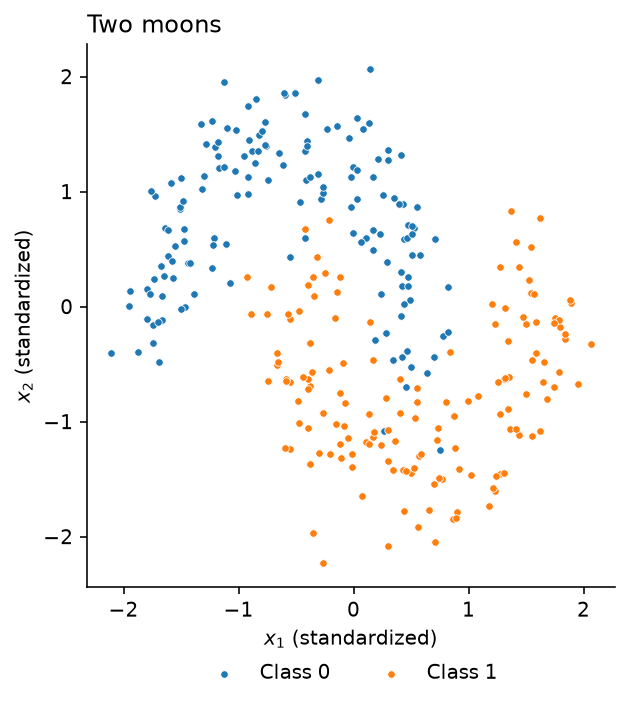

In [4]:
fig, ax = plt.subplots(figsize=(5, 4.5), dpi=144, layout="constrained")
for label, color in [(0, "C0"), (1, "C1")]:
    ax.scatter(
        *X[y == label].T,
        s=14,
        color=color,
        edgecolor="white",
        linewidth=0.4,
        label=f"Class {label}",
    )

ax.set(xlabel="$x_1$ (standardized)", ylabel="$x_2$ (standardized)", aspect="equal")
ax.set_title("Two moons", loc="left")
ax.spines[["top", "right"]].set_visible(False)

handles, labels = ax.get_legend_handles_labels()
fig.legend(
    handles=handles,
    labels=labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=False,
)
plt.show()

## Network

The network has two hidden layers of eight tanh units and a single output, the logit of $P(y = 1)$. Building it creates a shared variable for each weight matrix and bias vector, named after its layer: `hidden_1_W`, `hidden_1_b`, and so on. The symbolic input is named `X`.

In [5]:
n_hidden = 8

network = Sequential(
    Linear("hidden_1", n_in=2, n_out=n_hidden),
    Tanh(),
    Linear("hidden_2", n_in=n_hidden, n_out=n_hidden),
    Tanh(),
    Linear("output", n_in=n_hidden, n_out=1),
)

X_in = Input("X", shape=(None, 2))
logits = network(X_in)[:, 0]

## Model

The PyMC model gives each weight and bias a standard normal prior, declared under the name of the network parameter it replaces, and holds the inputs in a `pm.Data` container named `X`. `replace_with_model_variables` collects the network's parameters and inputs, looks up the model variable with each name, and rebuilds the network's output from those variables. The logits become a deterministic function of the priors and the data, and a Bernoulli likelihood links them to the observed labels.

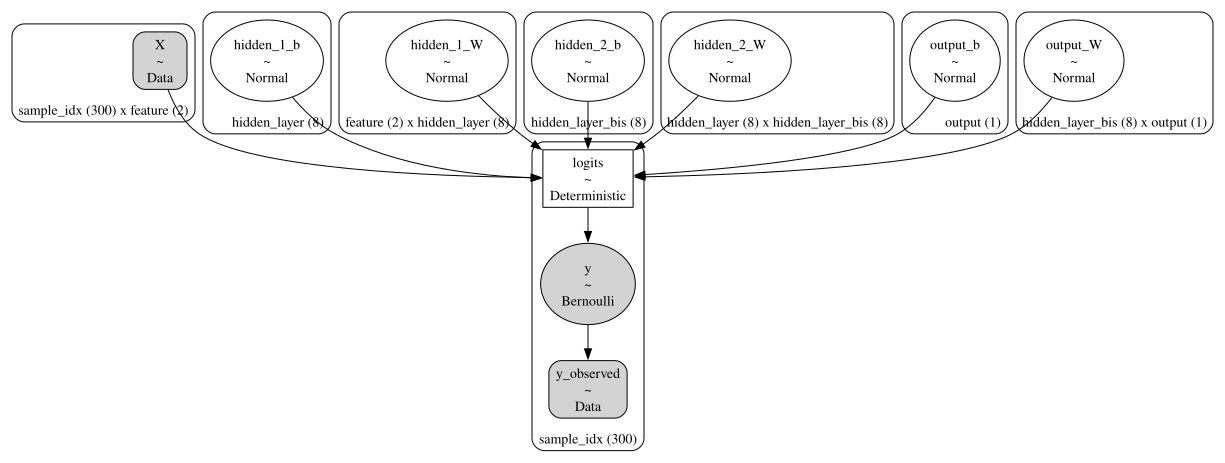

In [6]:
coords = {
    "feature": ["x1", "x2"],
    "sample_idx": range(X.shape[0]),
    "hidden_layer": range(n_hidden),
    "hidden_layer_bis": range(n_hidden),
    "output": ["class"],
}

with pm.Model(coords=coords) as model:
    X_data = pm.Data("X", X, dims=["sample_idx", "feature"])
    y_data = pm.Data("y_observed", y, dims=["sample_idx"])

    pm.Normal("hidden_1_b", mu=0.0, sigma=1.0, dims=["hidden_layer"])
    pm.Normal("hidden_1_W", mu=0.0, sigma=1.0, dims=["feature", "hidden_layer"])

    pm.Normal("hidden_2_b", mu=0.0, sigma=1.0, dims=["hidden_layer_bis"])
    pm.Normal("hidden_2_W", mu=0.0, sigma=1.0, dims=["hidden_layer", "hidden_layer_bis"])

    pm.Normal("output_b", mu=0.0, sigma=1.0, dims=["output"])
    pm.Normal("output_W", mu=0.0, sigma=1.0, dims=["hidden_layer_bis", "output"])

    model_logits = pm.Deterministic(
        "logits", replace_with_model_variables(logits), dims=["sample_idx"]
    )

    pm.Bernoulli(
        "y", logit_p=model_logits, observed=y_data, shape=X_data.shape[0], dims=["sample_idx"]
    )

model.to_graphviz()

## Sampling

PyMC samples the 105 weights and biases with NUTS {cite:p}`hoffman2014nuts`, running four chains of 1,000 draws each after 1,000 tuning steps.

In [7]:
with model:
    idata = pm.sample(random_seed=seed)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [hidden_1_b, hidden_1_W, hidden_2_b, hidden_2_W, output_b, output_W]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 19 seconds.
There was 1 divergence after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details


## Predictions

`grid_probability` swaps the data container for an 80 by 80 grid of points and recomputes the logits from every posterior draw. The sigmoid of each draw's logits is one draw of $P(y = 1)$ at each grid point, and the mean and standard deviation over draws summarize them. The function restores the training data afterwards, so later cells see the model as it was fit.

In [8]:
grid_size = 80
x1_grid, x2_grid = np.meshgrid(np.linspace(-2.5, 2.5, grid_size), np.linspace(-2.5, 2.5, grid_size))
X_grid = np.column_stack([x1_grid.ravel(), x2_grid.ravel()]).astype(floatX)


def grid_probability(model, idata):
    with model:
        pm.set_data(
            {"X": X_grid, "y_observed": np.zeros(len(X_grid), dtype=int)},
            coords={"sample_idx": range(len(X_grid))},
        )
        predictions = pm.sample_posterior_predictive(idata, var_names=["logits"], random_seed=seed)
        pm.set_data({"X": X, "y_observed": y}, coords={"sample_idx": range(len(X))})

    probabilities = 1 / (1 + np.exp(-predictions.posterior_predictive["logits"].values))
    mean = probabilities.mean(axis=(0, 1)).reshape(grid_size, grid_size)
    std = probabilities.std(axis=(0, 1)).reshape(grid_size, grid_size)
    return mean, std


probability_mean, probability_std = grid_probability(model, idata)

Sampling: []


Output()

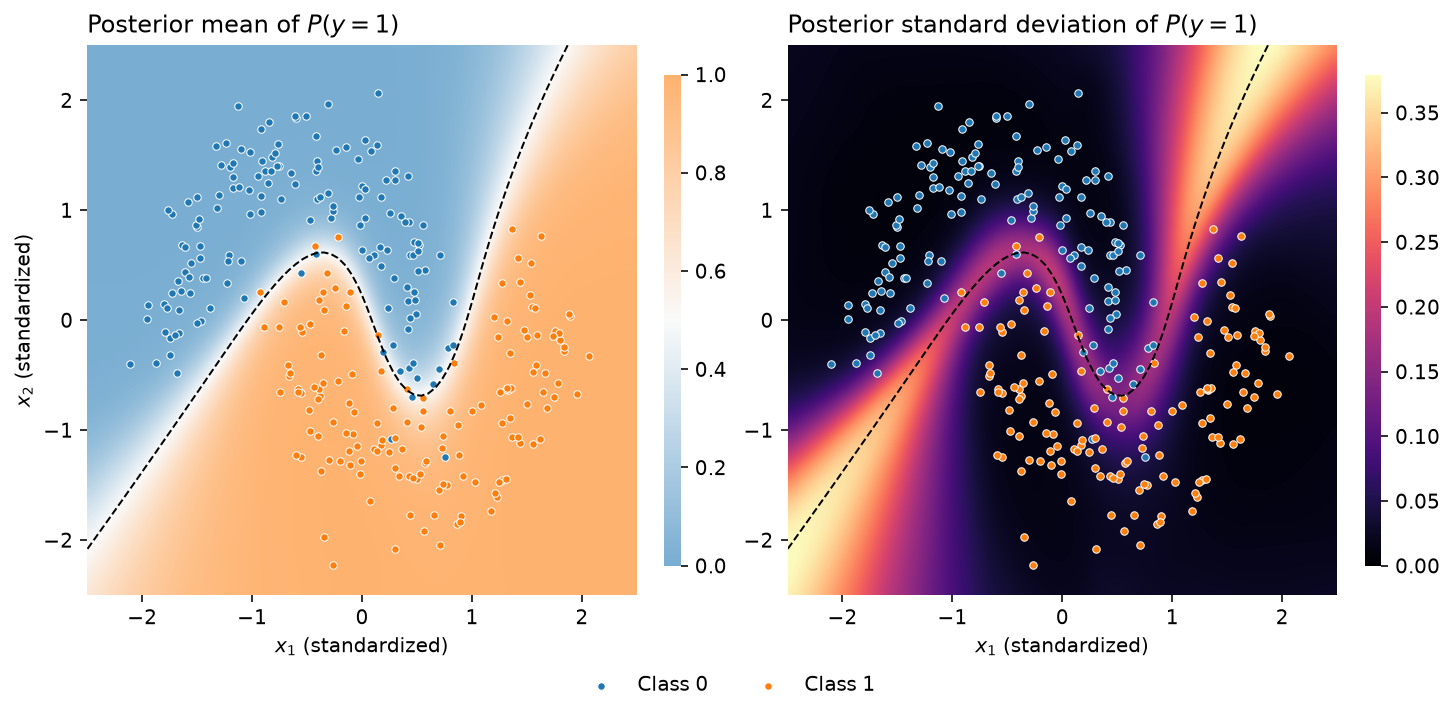

In [9]:
class_cmap = LinearSegmentedColormap.from_list(
    "class_probability", [to_rgb("C0"), (0.97, 0.97, 0.97), to_rgb("C1")]
)
extent = (x1_grid.min(), x1_grid.max(), x2_grid.min(), x2_grid.max())


def plot_probability_surfaces(probability_mean, probability_std):
    fig, axes = plt.subplots(ncols=2, figsize=(10, 4.6), dpi=144, layout="constrained")
    panels = [
        (axes[0], probability_mean, class_cmap, (0.0, 1.0), 0.6, "Posterior mean of $P(y = 1)$"),
        (
            axes[1],
            probability_std,
            "magma",
            (0.0, None),
            1.0,
            "Posterior standard deviation of $P(y = 1)$",
        ),
    ]

    for ax, values, cmap, (vmin, vmax), alpha, title in panels:
        image = ax.imshow(
            values,
            origin="lower",
            extent=extent,
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
            alpha=alpha,
            interpolation="bicubic",
            aspect="equal",
        )
        ax.contour(
            x1_grid,
            x2_grid,
            probability_mean,
            levels=[0.5],
            colors="black",
            linewidths=1.0,
            linestyles="--",
        )
        for label, color in [(0, "C0"), (1, "C1")]:
            ax.scatter(
                *X[y == label].T,
                s=14,
                color=color,
                edgecolor="white",
                linewidth=0.5,
                label=f"Class {label}",
            )

        colorbar = fig.colorbar(image, ax=ax, shrink=0.8, aspect=30)
        colorbar.outline.set_visible(False)
        ax.set(xlim=extent[:2], ylim=extent[2:], xlabel="$x_1$ (standardized)")
        ax.set_title(title, loc="left")
        ax.spines[:].set_visible(False)

    axes[0].set_ylabel("$x_2$ (standardized)")

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles=handles,
        labels=labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.07),
        ncol=len(labels),
        frameon=False,
    )
    plt.show()


plot_probability_surfaces(probability_mean, probability_std)

The posterior mean places the boundary between the two moons, and the standard deviation is close to zero wherever there is training data. It is largest along the two ends of the boundary, beyond the data, where the training points do not determine which way the boundary continues.

## Weights

Sampling the model without data gives draws from the prior over the weights. The plot compares prior and posterior for the eight output weights.

Sampling: [hidden_1_W, hidden_1_b, hidden_2_W, hidden_2_b, output_W, output_b]


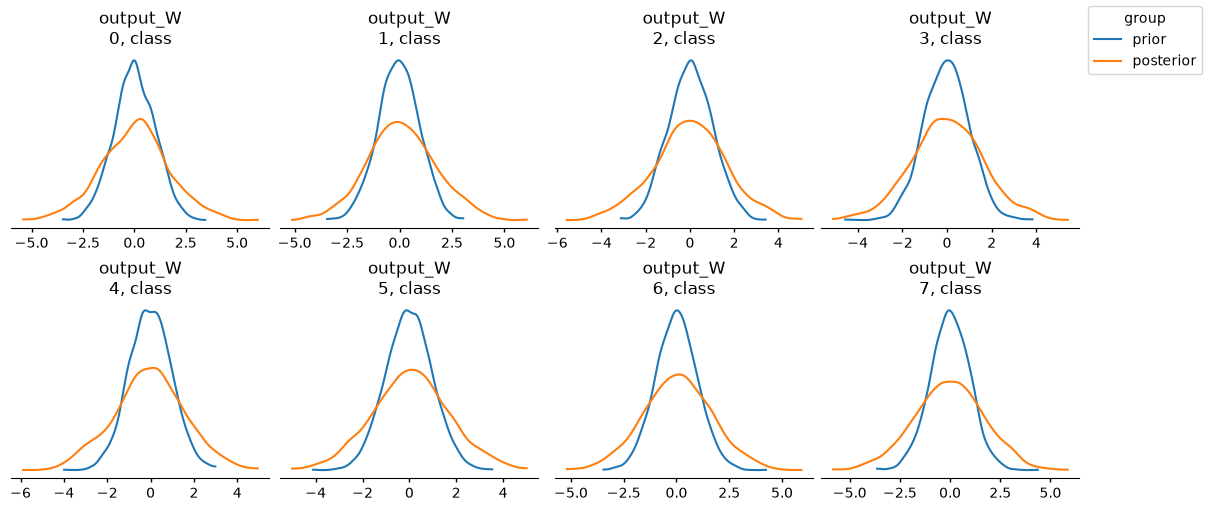

In [10]:
weight_names = [rv.name for rv in model.free_RVs]

with model:
    prior = pm.sample_prior_predictive(draws=4000, var_names=weight_names, random_seed=seed)
idata["prior"] = prior["prior"]

az.plot_prior_posterior(
    idata, var_names=["output_W"], figure_kwargs={"figsize": (12, 5), "layout": "constrained"}
)
plt.show()

Every output weight has a posterior centered at zero and wider than its prior, even though the network classifies the moons well. The network's symmetries explain this {cite:p}`chen1993geometry`. Negating a tanh unit's incoming weights, its bias, and its outgoing weight leaves the output unchanged, and so does permuting the units of a hidden layer. Each posterior mode therefore has many copies with weights negated or relabeled, and the marginal distribution of any one weight averages over all of them. The data constrain combinations of weights through the function they compute, and the marginal of a single weight hides those constraints.

## References

```{bibliography}
```

## Authors

- Created by Jesse Grabowski, November 8, 2026

## Watermark

In [11]:
%load_ext watermark
%watermark -n -u -v -iv -m -w

Last updated: Sun, 08 Nov 2026

Python implementation: CPython
Python version       : 3.14.10
IPython version      : 9.16.1

Compiler    : Clang 20.1.8 
OS          : Darwin
Release     : 25.6.0
Machine     : arm64
Processor   : arm
CPU cores   : 14
Architecture: 64bit

arviz      : 1.3.0
matplotlib : 3.11.2
numpy      : 2.5.4
pymc       : 6.4.0
pytensor   : 3.3.8
pytensor_ml: 0.4.0
sklearn    : 1.9.1

Watermark: 2.6.0



# Thumbnail Image

The cells below draw this notebook's card image for the docs gallery: five posterior draws of the network stacked as slices, with each edge colored by the weight or bias it carries. The `gallery-thumbnail` tag on the figure cell selects it as the thumbnail, and the `remove-cell` tag, shared by both cells and this heading, keeps all three off the rendered page.

In [12]:
layer_names = ["hidden_1", "hidden_2", "output"]
layer_symbols = ["1", "2", "o"]
layer_sizes = [2, n_hidden, n_hidden, 1]
weight_norm = Normalize(vmin=-3.0, vmax=3.0)

card_bounds = (-1.0, 7.0, -5.6, 4.3)
column_stretch = 1.6
slice_spacing = 2.5


def _column(x, size):
    return np.column_stack([np.full(size, x), np.linspace(-(size - 1) / 2, (size - 1) / 2, size)])


def network_columns():
    columns = [_column(0.0, layer_sizes[0])]
    for layer, size in enumerate(layer_sizes[1:]):
        columns += [_column(2 * layer + 1, size), _column(2 * layer + 2, size)]
    return columns


def slice_transform(depth):
    cos, sin = np.cos(np.pi / 6), np.sin(np.pi / 6)
    offset = slice_spacing * depth
    return Affine2D(
        np.array(
            [
                [cos * column_stretch, 0.0, -cos * offset],
                [sin * column_stretch, 1.0, sin * offset],
                [0.0, 0.0, 1.0],
            ]
        )
    )


def _draw_edges(ax, starts, ends, values, transform):
    edges = LineCollection(
        np.stack([starts, ends], axis=1),
        cmap="RdBu_r",
        norm=weight_norm,
        zorder=1,
        transform=transform,
        linewidths=0.3 + 1.5 * np.abs(values) / weight_norm.vmax,
    )
    edges.set_array(values)
    ax.add_collection(edges)
    return edges


def plot_network(idata, *, chain, draw, ax, transform):
    posterior = idata.posterior.isel(chain=chain, draw=draw)
    columns = network_columns()
    to_axes = transform + ax.transData

    for layer, name in enumerate(layer_names):
        previous, summed, biased = columns[2 * layer : 2 * layer + 3]
        weights = posterior[f"{name}_W"].values
        biases = posterior[f"{name}_b"].values

        sources, targets = np.meshgrid(
            np.arange(len(previous)), np.arange(len(summed)), indexing="ij"
        )
        _draw_edges(
            ax, previous[sources.ravel()], summed[targets.ravel()], weights.ravel(), to_axes
        )
        edges = _draw_edges(ax, summed, biased, biases, to_axes)

    for column in columns:
        ax.scatter(
            *column.T,
            color="white",
            s=30,
            edgecolor="0.2",
            linewidth=0.5,
            zorder=1,
            transform=to_axes,
        )
    return edges


def label_network(ax, *, transform):
    columns = network_columns()
    to_axes = transform + ax.transData
    label_height = -(max(layer_sizes) - 1) / 2 - 1.0

    for layer, symbol in enumerate(layer_symbols):
        summed, biased = columns[2 * layer + 1 : 2 * layer + 3]
        for column, label in [(summed, rf"$W_{{{symbol}}}$"), (biased, rf"$b_{{{symbol}}}$")]:
            ax.text(
                column[0, 0],
                label_height,
                label,
                ha="center",
                va="baseline",
                fontsize=10,
                transform=to_axes,
            )

    for position, label in zip(columns[0], ["$x_1$", "$x_2$"]):
        ax.annotate(
            label,
            position,
            xycoords=to_axes,
            xytext=(-8, 0),
            textcoords="offset points",
            ha="right",
            va="center",
        )
    ax.annotate(
        r"$\hat{y}$",
        columns[-1][0],
        xycoords=to_axes,
        xytext=(8, 0),
        textcoords="offset points",
        ha="left",
        va="center",
    )

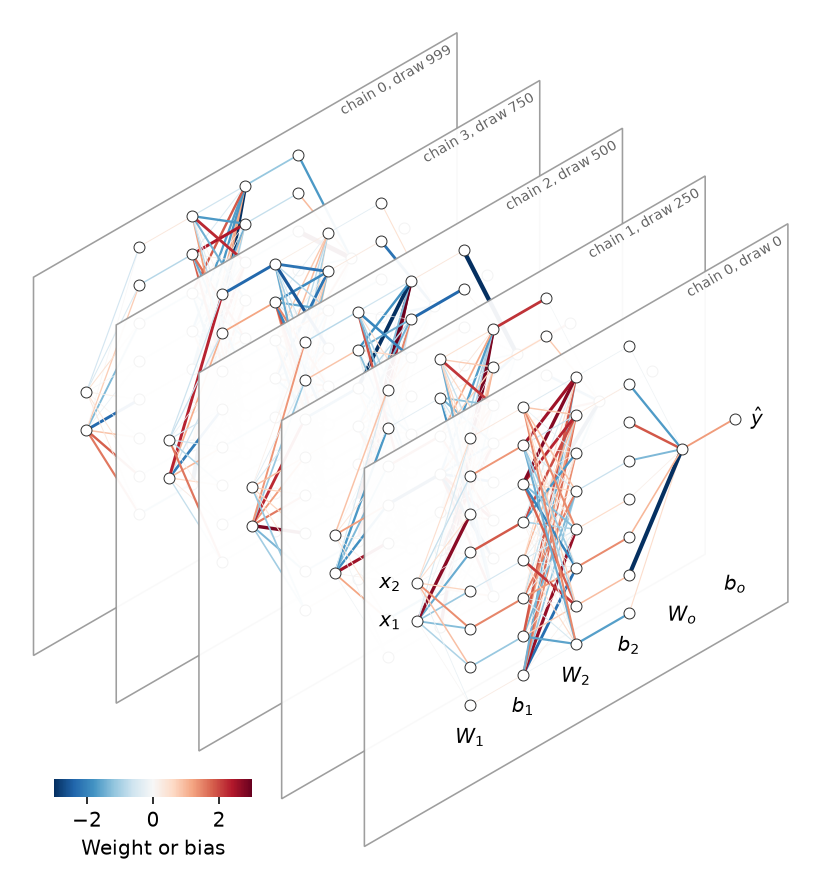

In [13]:
draws = [(0, 0), (1, 250), (2, 500), (3, 750), (0, 999)]
u_min, u_max, v_min, v_max = card_bounds
card_corners = np.array([[u_min, v_min], [u_max, v_min], [u_max, v_max], [u_min, v_max]])

fig, ax = plt.subplots(figsize=(6, 6), dpi=144, layout="constrained")
for depth, (chain, draw) in reversed(list(enumerate(draws))):
    to_axes = slice_transform(depth) + ax.transData
    ax.add_patch(
        Polygon(
            card_corners,
            transform=to_axes,
            facecolor="white",
            edgecolor="0.6",
            linewidth=0.8,
            alpha=0.95,
            zorder=1,
        )
    )
    edges = plot_network(idata, chain=chain, draw=draw, ax=ax, transform=slice_transform(depth))
    ax.annotate(
        f"chain {chain}, draw {draw}",
        (u_max, v_max),
        xycoords=to_axes,
        xytext=(-5, -5),
        textcoords="offset points",
        ha="right",
        va="top",
        rotation=30,
        rotation_mode="anchor",
        fontsize=7,
        color="0.4",
    )
label_network(ax, transform=slice_transform(0))

projected = np.concatenate(
    [slice_transform(depth).transform(card_corners) for depth in range(len(draws))]
)
ax.set_xlim(projected[:, 0].min() - 0.5, projected[:, 0].max() + 0.5)
ax.set_ylim(projected[:, 1].min() - 0.5, projected[:, 1].max() + 0.5)
ax.set_aspect("equal")
ax.set_axis_off()

colorbar_axes = ax.inset_axes([0.05, 0.08, 0.25, 0.022])
colorbar = fig.colorbar(edges, cax=colorbar_axes, orientation="horizontal", label="Weight or bias")
colorbar.outline.set_visible(False)
plt.show()